In [38]:
print("hello world")


hello world


In [39]:

import pandas as pd
import numpy as np
import glob
import os

In [40]:
data_folder = "data/raw"

csv_files = glob.glob(os.path.join(data_folder, "*.csv"))
print("Found files:", csv_files)

all_dfs = []

for file in csv_files:
     city_name = os.path.basename(file).split("_weather")[0] 
     df_city = pd.read_csv(file, skiprows=3)
     df_city.columns = ['date', 'temp_max', 'temp_min', 'precip', 'wind_max', 'humidity', 'pressure', 'weathercode']
     df_city['city'] = city_name
     all_dfs.append(df_city)

df = pd.concat(all_dfs, ignore_index=True)
print("Combined shape:", df.shape)
df.head()

Found files: ['data/raw/Jaipur_weather.csv', 'data/raw/Chennai_weather.csv', 'data/raw/Guwahati_weather.csv', 'data/raw/Kolkata_weather.csv', 'data/raw/Mumbai_weather.csv', 'data/raw/Delhi_weather.csv', 'data/raw/Shimla_weather.csv', 'data/raw/Pune_weather.csv']
Combined shape: (29232, 9)


,date,temp_max,temp_min,precip,wind_max,humidity,pressure,weathercode,city
0,2015-01-01,19.2,11.1,0.0,17.8,79,1016.7,3,Jaipur
1,2015-01-02,18.1,11.7,0.0,16.0,78,1017.2,3,Jaipur
2,2015-01-03,18.7,8.1,0.0,6.7,80,1017.7,3,Jaipur
3,2015-01-04,20.3,7.5,0.0,9.3,73,1019.8,3,Jaipur
4,2015-01-05,22.3,8.0,0.0,15.3,67,1017.1,0,Jaipur


In [41]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['city', 'date']).reset_index(drop=True)
df.dtypes


date           datetime64[us]
temp_max              float64
temp_min              float64
precip                float64
wind_max              float64
humidity                int64
pressure              float64
weathercode             int64
city                      str
dtype: object

In [42]:
print(df)

            date  temp_max  temp_min  precip  wind_max  humidity  pressure  \
0     2015-01-01      28.7      22.0     0.2      10.2        87    1009.7   
1     2015-01-02      28.6      23.3     0.8      13.2        87    1012.2   
2     2015-01-03      28.4      23.0     2.0       9.7        90    1012.8   
3     2015-01-04      28.3      21.8     0.5      10.7        85    1012.9   
4     2015-01-05      28.4      21.6     0.1      14.4        83    1012.6   
...          ...       ...       ...     ...       ...       ...       ...   
29227 2024-12-28       8.0      -1.4    18.7      11.5        88    1020.2   
29228 2024-12-29      11.9      -1.8     0.0      13.0        74    1020.6   
29229 2024-12-30      14.3      -1.1     0.0      11.6        51    1018.8   
29230 2024-12-31      14.6       1.3     0.0       8.8        52    1019.0   
29231 2025-01-01      15.8       2.5     0.0      12.3        33    1017.5   

       weathercode     city  
0               51  Chennai  
1  

In [43]:
print("Duplicates:", df.duplicated(['city', 'date']).sum())
print("Nulls:\n", df.isnull().sum())
print(df.groupby('city')['date'].agg(['min', 'max', 'count']))
gaps = df.groupby('city')['date'].diff().dt.days
print("Day gaps more than 1:", (gaps.dropna() != 1).sum())

Duplicates: 0
Nulls:
 date           0
temp_max       0
temp_min       0
precip         0
wind_max       0
humidity       0
pressure       0
weathercode    0
city           0
dtype: int64
                min        max  count
city                                 
Chennai  2015-01-01 2025-01-01   3654
Delhi    2015-01-01 2025-01-01   3654
Guwahati 2015-01-01 2025-01-01   3654
Jaipur   2015-01-01 2025-01-01   3654
Kolkata  2015-01-01 2025-01-01   3654
Mumbai   2015-01-01 2025-01-01   3654
Pune     2015-01-01 2025-01-01   3654
Shimla   2015-01-01 2025-01-01   3654
Day gaps more than 1: 0


In [44]:
train_list = []
val_list = []
test_list = []

for city in df['city'].unique():
    city_df = df[df['city'] == city]      # only this city's rows (already sorted by date)
    n = len(city_df)                      # 3654 rows

    train_end = int(n * 0.70)             # 2557
    val_end   = int(n * 0.85)             # 3105

    train_list.append(city_df[:train_end])           # first 70%
    val_list.append(city_df[train_end:val_end])      # next 15%
    test_list.append(city_df[val_end:])              # last 15%


train_df = pd.concat(train_list)
val_df   = pd.concat(val_list)
test_df  = pd.concat(test_list)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Train: 20456 Val: 4384 Test: 4392


In [45]:
from sklearn.preprocessing import MinMaxScaler

features = ['temp_max', 'temp_min', 'precip', 'wind_max', 'humidity', 'pressure', 'weathercode']
scaler=MinMaxScaler()

scaler.fit(train_df[features])
# 2. Apply the same scaling to all three sets
train_df = train_df.copy()
val_df   = val_df.copy()
test_df  = test_df.copy()

train_df[features] = scaler.transform(train_df[features])
val_df[features]   = scaler.transform(val_df[features])
test_df[features]  = scaler.transform(test_df[features])

print(train_df[features].describe().loc[['min', 'max']])


     temp_max  temp_min  precip  wind_max  humidity  pressure  weathercode
min       0.0       0.0     0.0       0.0       0.0       0.0          0.0
max       1.0       1.0     1.0       1.0       1.0       1.0          1.0


In [46]:
print(test_df.head())

           date  temp_max  temp_min    precip  wind_max  humidity  pressure  \
3105 2023-07-03  0.716814  0.825503  0.049098  0.266975  0.758242  0.469657   
3106 2023-07-04  0.694690  0.816555  0.067635  0.208333  0.813187  0.430079   
3107 2023-07-05  0.738938  0.825503  0.090681  0.259259  0.747253  0.411609   
3108 2023-07-06  0.688053  0.852349  0.000501  0.274691  0.703297  0.490765   
3109 2023-07-07  0.736726  0.845638  0.002004  0.234568  0.648352  0.535620   

      weathercode     city  
3105     0.840000  Chennai  
3106     0.840000  Chennai  
3107     0.866667  Chennai  
3108     0.680000  Chennai  
3109     0.680000  Chennai  


In [48]:
window = 30    # look back 30 days
horizon = 7    # predict next 7 days

def make_windows(data_df):
    X = []
    y = []
    for city in data_df['city'].unique():
        values = data_df[data_df['city'] == city][features].values   # this city only, as numbers

        for i in range(len(values) - window - horizon + 1):
            X.append(values[i : i + window])                         # 30 days, all 7 features
            y.append(values[i + window : i + window + horizon, 0])  # next 7 days, temp_max only (column 0)

    return np.array(X), np.array(y)

X_train, y_train = make_windows(train_df)
X_val,   y_val   = make_windows(val_df)
X_test,  y_test  = make_windows(test_df)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape,   y_val.shape)
print("Test: ", X_test.shape,  y_test.shape)


Train: (20168, 30, 7) (20168, 7)
Val:   (4096, 30, 7) (4096, 7)
Test:  (4104, 30, 7) (4104, 7)


In [ ]:
from sklearn.metrics import root_mean_squared_error

# Helper: convert scaled temp_max (0-1) back to °C
t_min   = scaler.data_min_[0]
t_range = scaler.data_max_[0] - scaler.data_min_[0]

def to_celsius(x):
    return x * t_range + t_min

# 1. Last day's temp_max from every window
last_temp = X_test[:, -1, 0]          # all windows, last day (-1), temp_max (0) → shape (4104,)

# 2. Repeat it 7 times → same temp for all 7 future days
baseline_pred = np.repeat(last_temp.reshape(-1, 1), 7, axis=1)   # shape (4104, 7)

# 3. Convert both to °C
y_test_c        = to_celsius(y_test)
baseline_pred_c = to_celsius(baseline_pred)

# 4. RMSE for each forecast day
baseline_rmse = []
for day in range(7):
    rmse = root_mean_squared_error(y_test_c[:, day], baseline_pred_c[:, day])
    baseline_rmse.append(rmse)
    print(f"Day {day+1} RMSE: {rmse:.2f} °C")

print(f"Average RMSE: {np.mean(baseline_rmse):.2f} °C")


Day 1 RMSE: 1.34 °C
Day 2 RMSE: 1.77 °C
Day 3 RMSE: 2.03 °C
Day 4 RMSE: 2.20 °C
Day 5 RMSE: 2.33 °C
Day 6 RMSE: 2.44 °C
Day 7 RMSE: 2.53 °C
Average RMSE: 2.09 °C


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5),
    ModelCheckpoint('models/best_lstm.keras', monitor='val_loss', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)


Epoch 1/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - loss: 0.0205 - mae: 0.1017 - val_loss: 0.0037 - val_mae: 0.0469 - learning_rate: 0.0010
Epoch 2/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - loss: 0.0066 - mae: 0.0638 - val_loss: 0.0037 - val_mae: 0.0475 - learning_rate: 0.0010
Epoch 3/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - loss: 0.0047 - mae: 0.0533 - val_loss: 0.0030 - val_mae: 0.0412 - learning_rate: 0.0010
Epoch 4/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - loss: 0.0037 - mae: 0.0470 - val_loss: 0.0029 - val_mae: 0.0408 - learning_rate: 0.0010
Epoch 5/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - loss: 0.0031 - mae: 0.0430 - val_loss: 0.0028 - val_mae: 0.0405 - learning_rate: 0.0010
Epoch 6/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - loss: 0.0027 - mae: 0.0401 - val_loss: 0.0027 - val_mae: 0.0388 - learning_rate: 0.0010
Epoch 7/100
631/631 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - loss: 0.0025 - mae: 0.0383 - val_loss: 0.0026 - val_mae: 0.0381 - learnin

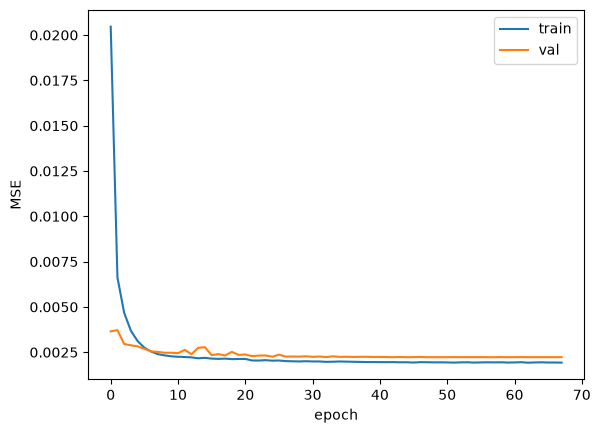

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend()
plt.show()


In [ ]:
# Predict on test data (scaled 0-1)
lstm_pred = model.predict(X_test)

# Convert to °C
lstm_pred_c = to_celsius(lstm_pred)

# RMSE per day: LSTM vs baseline
lstm_rmse = []
print("Day | Baseline | LSTM  | Better?")
for day in range(7):
    rmse = root_mean_squared_error(y_test_c[:, day], lstm_pred_c[:, day])
    lstm_rmse.append(rmse)
    better = "✅" if rmse < baseline_rmse[day] else "❌"
    print(f" {day+1}  |  {baseline_rmse[day]:.2f}    | {rmse:.2f}  | {better}")

print(f"\nAverage → Baseline: {np.mean(baseline_rmse):.2f} °C | LSTM: {np.mean(lstm_rmse):.2f} °C")


129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Day | Baseline | LSTM  | Better?
 1  |  1.34    | 1.30  | ✅
 2  |  1.77    | 1.64  | ✅
 3  |  2.03    | 1.82  | ✅
 4  |  2.20    | 1.94  | ✅
 5  |  2.33    | 2.02  | ✅
 6  |  2.44    | 2.08  | ✅
 7  |  2.53    | 2.14  | ✅

Average → Baseline: 2.09 °C | LSTM: 1.85 °C


In [ ]:
# Rebuild city + date for each test window (same loop order as make_windows)
rows = []
for city in test_df['city'].unique():
    dates = test_df[test_df['city'] == city]['date'].values
    for i in range(len(dates) - window - horizon + 1):
        rows.append({'city': city, 'forecast_date': dates[i + window]})   # first predicted day

results = pd.DataFrame(rows)
print(len(results), len(X_test))   # must be equal

# Day-1 forecast: actual vs predicted
results['actual']    = y_test_c[:, 0].round(1)
results['predicted'] = lstm_pred_c[:, 0].round(1)
results['error']     = (results['predicted'] - results['actual']).round(1)

results.sample(15, random_state=42)


4104 4104


,city,forecast_date,actual,predicted,error
1295,Guwahati,2024-04-27,34.7,34.3,-0.4
4018,Shimla,2024-10-02,22.2,21.8,-0.4
2459,Kolkata,2024-09-12,31.4,31.5,0.1
2872,Mumbai,2024-06-04,33.5,34.3,0.8
2963,Mumbai,2024-09-03,27.3,27.5,0.2
4088,Shimla,2024-12-11,14.6,12.5,-2.1
1905,Jaipur,2024-08-02,30.3,29.7,-0.6
1395,Guwahati,2024-08-05,30.0,32.2,2.2
2179,Kolkata,2023-12-07,21.7,27.0,5.3
4103,Shimla,2024-12-26,12.8,10.6,-2.2


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

print("Day |  MAE  | RMSE |  R²   | within ±2°C")
for day in range(7):
    actual = y_test_c[:, day]
    pred   = lstm_pred_c[:, day]

    mae  = mean_absolute_error(actual, pred)
    rmse = root_mean_squared_error(actual, pred)
    r2   = r2_score(actual, pred)
    acc2 = (np.abs(actual - pred) <= 2).mean() * 100

    print(f" {day+1}  | {mae:.2f}  | {rmse:.2f} | {r2:.3f} | {acc2:.1f}%")


Day |  MAE  | RMSE |  R²   | within ±2°C
 1  | 0.95  | 1.30 | 0.954 | 89.4%
 2  | 1.21  | 1.64 | 0.928 | 81.4%
 3  | 1.35  | 1.82 | 0.911 | 76.8%
 4  | 1.45  | 1.94 | 0.900 | 75.0%
 5  | 1.52  | 2.02 | 0.892 | 72.5%
 6  | 1.57  | 2.08 | 0.885 | 71.3%
 7  | 1.61  | 2.14 | 0.879 | 69.7%


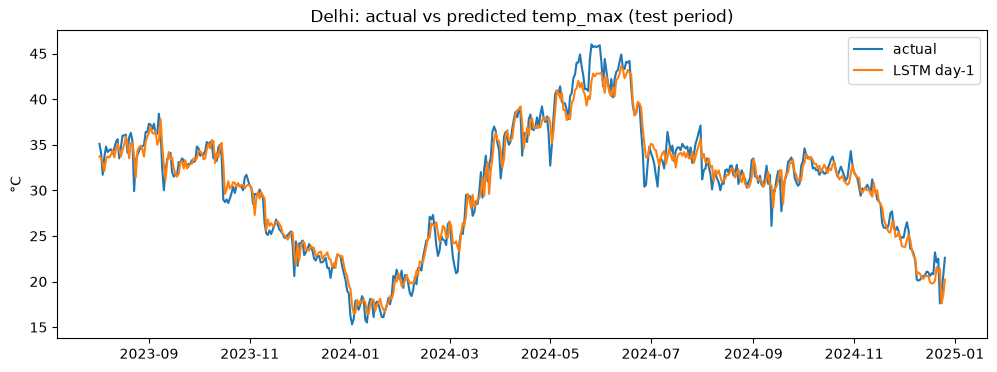

In [ ]:
city = 'Delhi'
mask = results['city'] == city

plt.figure(figsize=(12, 4))
plt.plot(results.loc[mask, 'forecast_date'], results.loc[mask, 'actual'],    label='actual')
plt.plot(results.loc[mask, 'forecast_date'], results.loc[mask, 'predicted'], label='LSTM day-1')
plt.title(f'{city}: actual vs predicted temp_max (test period)')
plt.ylabel('°C'); plt.legend(); plt.show()


In [ ]:
import joblib
import json

# 1. The trained model (best weights, already restored by EarlyStopping)
model.save('models/lstm_weather_model.keras')

# 2. The scaler: needed to scale new input and convert predictions back to °C
joblib.dump(scaler, 'models/scaler.pkl')

# 3. Settings the model depends on: needed later to build input correctly
config = {
    'features': features,   # column order matters
    'target': 'temp_max',
    'window': window,       # 30
    'horizon': horizon,     # 7
}
with open('models/config.json', 'w') as f:
    json.dump(config, f, indent=2)

# 4. Test results: your F1 evidence for the demo
metrics = {
    'baseline_rmse': [round(float(x), 3) for x in baseline_rmse],
    'lstm_rmse':     [round(float(x), 3) for x in lstm_rmse],
    'baseline_avg':  round(float(np.mean(baseline_rmse)), 3),
    'lstm_avg':      round(float(np.mean(lstm_rmse)), 3),
}
with open('models/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print("Saved:", os.listdir('models'))


Saved: ['metrics.json', 'lstm_weather_model.keras', 'best_lstm.keras', 'config.json', '.gitkeep', 'scaler.pkl']


Valid start dates: 2023-08-02 to 2024-12-26

=== Shimla: last 30 days (input) ===
      date  temp_max  temp_min  humidity  precip
2024-11-10      17.8       6.6        80     0.0
2024-11-11      17.7       6.3        76     0.7
2024-11-12      17.3       5.9        73     0.0
2024-11-13      18.3       6.4        57     0.0
2024-11-14      18.1       5.8        62     0.0
2024-11-15      17.6       5.5        62     0.0
2024-11-16      15.4       4.1        64     0.0
2024-11-17      16.4       4.0        67     0.0
2024-11-18      16.5       4.3        70     0.0
2024-11-19      16.1       4.0        70     0.0
2024-11-20      15.9       3.9        65     0.0
2024-11-21      16.3       3.9        66     0.0
2024-11-22      14.7       4.3        64     0.0
2024-11-23      14.6       4.2        63     0.0
2024-11-24      14.8       3.4        58     0.0
2024-11-25      14.1       2.8        63     0.0
2024-11-26      13.7       2.5        65     0.0
2024-11-27      13.5       2.3      

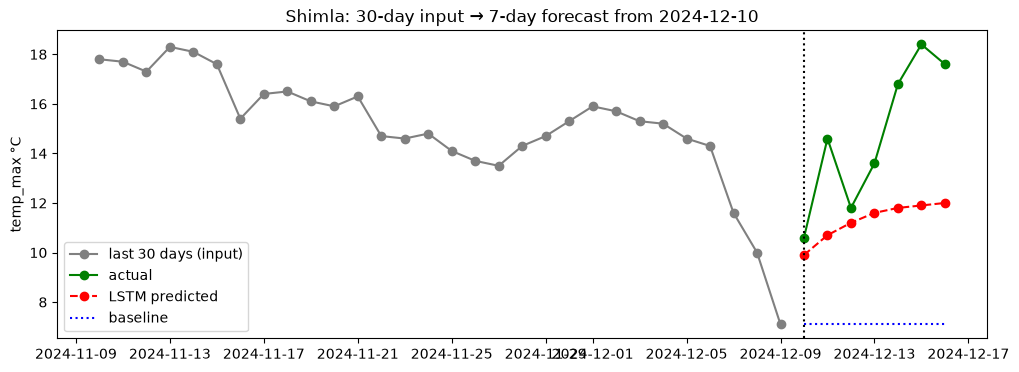

In [ ]:
city  = 'Shimla'
start = '2024-12-10'          # first day to forecast

# Which dates can you pick? (test period, after the first 30 days)
valid = results[results['city'] == city]['forecast_date']
print("Valid start dates:", valid.min().date(), "to", valid.max().date())

# Find this window's number in X_test
idx = results[(results['city'] == city) &
              (results['forecast_date'] == pd.Timestamp(start))].index[0]

city_df = df[df['city'] == city]   # original data in °C

# 1. Last 30 days: what the model saw as input
past = city_df[city_df['date'] < start].tail(30)
print(f"\n=== {city}: last 30 days (input) ===")
print(past[['date', 'temp_max', 'temp_min', 'humidity', 'precip']].to_string(index=False))

# 2. Next 7 days: actual vs predicted
future = city_df[city_df['date'] >= start].head(7)[['date', 'temp_max']].copy()
future = future.rename(columns={'temp_max': 'actual'})
future['predicted'] = lstm_pred_c[idx].round(1)
future['baseline']  = baseline_pred_c[idx].round(1)
future['error']     = (future['predicted'] - future['actual']).round(1)
print(f"\n=== {city}: next 7 days (forecast) ===")
print(future.to_string(index=False))

# 3. Plot
plt.figure(figsize=(12, 4))
plt.plot(past['date'],   past['temp_max'],      'o-', color='gray',  label='last 30 days (input)')
plt.plot(future['date'], future['actual'],      'o-', color='green', label='actual')
plt.plot(future['date'], future['predicted'],   'o--', color='red',  label='LSTM predicted')
plt.plot(future['date'], future['baseline'],    ':',  color='blue',  label='baseline')
plt.axvline(pd.Timestamp(start), color='black', linestyle=':')
plt.title(f'{city}: 30-day input → 7-day forecast from {start}')
plt.ylabel('temp_max °C'); plt.legend(); plt.show()


In [ ]:
def show_forecast(city, start):
    idx = results[(results['city'] == city) &
                  (results['forecast_date'] == pd.Timestamp(start))].index[0]

    dates = pd.date_range(start, periods=7)          # the 7 forecast days
    table = pd.DataFrame({
        'city':          city,
        'forecast_date': dates.date,
        'actual':        y_test_c[idx].round(1),
        'predicted':     lstm_pred_c[idx].round(1),
        'baseline':      baseline_pred_c[idx].round(1),
    })
    table['error'] = (table['predicted'] - table['actual']).round(1)
    return table

pd.concat([
    show_forecast('Pune',   '2024-06-01'),
    show_forecast('Delhi',  '2024-05-15'),
    show_forecast('Shimla', '2024-12-10'),
], ignore_index=True)


,city,forecast_date,actual,predicted,baseline,error
0,Pune,2024-06-01,35.9,36.0,35.8,0.1
1,Pune,2024-06-02,36.2,36.0,35.8,-0.2
2,Pune,2024-06-03,37.4,35.9,35.8,-1.5
3,Pune,2024-06-04,31.4,35.9,35.8,4.5
4,Pune,2024-06-05,33.2,35.9,35.8,2.7
5,Pune,2024-06-06,33.6,35.9,35.8,2.3
6,Pune,2024-06-07,33.9,35.9,35.8,2.0
7,Delhi,2024-05-15,42.3,39.9,40.7,-2.4
8,Delhi,2024-05-16,42.7,39.8,40.7,-2.9
9,Delhi,2024-05-17,44.0,39.8,40.7,-4.2


In [ ]:
results['bias_day1'] = lstm_pred_c[:, 0] - y_test_c[:, 0]
results['abs_err_day1'] = np.abs(results['bias_day1'])
results['month'] = pd.to_datetime(results['forecast_date']).dt.month

print("Avg absolute error (day 1) by city:")
print(results.groupby('city')['abs_err_day1'].mean().round(2).sort_values())

print("\nBias (day 1) by city × month  (+ = too hot, − = too cold):")
print(results.pivot_table(index='city', columns='month', values='bias_day1').round(1))

print("\nWorst 10 forecasts:")
print(results.sort_values('abs_err_day1', ascending=False).head(10)[['city', 'forecast_date', 'actual', 'predicted', 'error']])


Avg absolute error (day 1) by city:
city
Pune        0.79
Mumbai      0.82
Chennai     0.97
Jaipur      0.97
Shimla      0.99
Delhi       0.99
Guwahati    1.01
Kolkata     1.03
Name: abs_err_day1, dtype: float64

Bias (day 1) by city × month  (+ = too hot, − = too cold):
month      1    2    3    4    5    6    7    8    9    10   11   12
city                                                                
Chennai   0.2 -0.1  0.0 -0.4 -0.8 -0.5 -0.6 -0.4 -0.4  0.0  0.5  0.1
Delhi     0.3  0.2 -0.0  0.0 -1.5 -0.1 -0.3 -0.1  0.0  0.0  0.1 -0.0
Guwahati  0.1 -0.1  0.2 -0.7  0.2  0.2 -0.2  0.2 -0.0  0.2  0.0  0.2
Jaipur   -0.1  0.5  0.2  0.3 -2.1  0.3 -0.2  0.1 -0.1  0.1 -0.1 -0.2
Kolkata   0.1 -0.1 -0.4 -1.3 -0.1 -0.1 -0.3 -0.1 -0.1  0.1  0.1 -0.2
Mumbai    0.4  0.1  0.3 -0.3 -0.1  0.2  0.0 -0.0 -0.0 -0.3  0.2 -0.1
Pune      0.1  0.1  0.2 -0.6  0.0  0.5  0.1 -0.3 -0.1  0.0  0.1 -0.1
Shimla    0.3  0.5  0.3  0.1 -0.3  1.0  0.2  0.3  0.1  0.4  0.6  0.2

Worst 10 forecasts:
          city fo